In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../Dataset/Website_Traffic_Analysis_Dataset.csv")

In [4]:
df.head()

,Session_ID,User_ID,Date,Traffic_Source,Device,Page_Visited,Session_Duration,Pages_Per_Session,Bounce,Conversion
0,S00215,U01730,2025-01-01,Direct,Tablet,/blog,417.4,2,0,0
1,S00240,U01204,2025-01-01,Organic,Mobile,/about,500.9,2,0,0
2,S00806,U01733,2025-01-01,Organic,Desktop,/contact,98.5,4,0,1
3,S00256,U01989,2025-01-02,Direct,Mobile,/,182.4,1,1,0
4,S00318,U01249,2025-01-02,Direct,Mobile,/product-details,195.4,3,0,0


In [5]:
df.shape

(2000, 10)

In [6]:
df.columns

Index(['Session_ID', 'User_ID', 'Date', 'Traffic_Source', 'Device',
       'Page_Visited', 'Session_Duration', 'Pages_Per_Session', 'Bounce',
       'Conversion'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Session_ID         2000 non-null   str    
 1   User_ID            2000 non-null   str    
 2   Date               2000 non-null   str    
 3   Traffic_Source     2000 non-null   str    
 4   Device             2000 non-null   str    
 5   Page_Visited       2000 non-null   str    
 6   Session_Duration   2000 non-null   float64
 7   Pages_Per_Session  2000 non-null   int64  
 8   Bounce             2000 non-null   int64  
 9   Conversion         2000 non-null   int64  
dtypes: float64(1), int64(3), str(6)
memory usage: 238.2 KB


In [8]:
df.describe()

,Session_Duration,Pages_Per_Session,Bounce,Conversion
count,2000.00000,2000.000000,2000.000000,2000.000000
mean,216.73840,2.627000,0.421000,0.074500
std,152.66691,1.835635,0.493843,0.262649
min,5.00000,1.000000,0.000000,0.000000
25%,106.07500,1.000000,0.000000,0.000000
50%,183.30000,2.000000,0.000000,0.000000
75%,293.42500,4.000000,1.000000,0.000000
max,1312.10000,11.000000,1.000000,1.000000


In [9]:
df.isnull().sum()

Session_ID           0
User_ID              0
Date                 0
Traffic_Source       0
Device               0
Page_Visited         0
Session_Duration     0
Pages_Per_Session    0
Bounce               0
Conversion           0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.dtypes

Session_ID               str
User_ID                  str
Date                     str
Traffic_Source           str
Device                   str
Page_Visited             str
Session_Duration     float64
Pages_Per_Session      int64
Bounce                 int64
Conversion             int64
dtype: object

In [12]:
df["Date"] = pd.to_datetime(df["Date"])

In [13]:
df["Date"].dtype

dtype('<M8[us]')

In [14]:
df["Session_ID"].nunique()

2000

In [15]:
df["Traffic_Source"].unique()

<ArrowStringArray>
['Direct', 'Organic', 'Paid', 'Referral', 'Social']
Length: 5, dtype: str

In [16]:
df["Device"].unique()

<ArrowStringArray>
['Tablet', 'Mobile', 'Desktop']
Length: 3, dtype: str

In [17]:
print(df["Bounce"].unique())
print(df["Conversion"].unique())

[0 1]
[0 1]


In [18]:
total_sessions = df["Session_ID"].count()

print("Total Sessions:", total_sessions)

Total Sessions: 2000


In [19]:
total_users = df["User_ID"].nunique()

print("Total Unique Users:", total_users)

Total Unique Users: 1076


In [20]:
avg_duration = df["Session_Duration"].mean()

print("Average Session Duration:", round(avg_duration, 2), "seconds")

Average Session Duration: 216.74 seconds


In [21]:
avg_pages = df["Pages_Per_Session"].mean()

print("Average Pages Per Session:", round(avg_pages, 2))

Average Pages Per Session: 2.63


In [22]:
bounce_rate = df["Bounce"].mean() * 100

print("Bounce Rate:", round(bounce_rate, 2), "%")

Bounce Rate: 42.1 %


In [23]:
conversion_rate = df["Conversion"].mean() * 100

print("Conversion Rate:", round(conversion_rate, 2), "%")

Conversion Rate: 7.45 %


In [24]:
traffic_counts = df["Traffic_Source"].value_counts()

print(traffic_counts)

Traffic_Source
Organic     711
Paid        444
Direct      387
Social      246
Referral    212
Name: count, dtype: int64


In [25]:
traffic_percentage = df["Traffic_Source"].value_counts(normalize=True) * 100

print(traffic_percentage.round(2))

Traffic_Source
Organic     35.55
Paid        22.20
Direct      19.35
Social      12.30
Referral    10.60
Name: proportion, dtype: float64


In [26]:
traffic_summary = df.groupby("Traffic_Source").agg(
    Total_Sessions=("Session_ID", "count"),
    Total_Conversions=("Conversion", "sum"),
    Average_Duration=("Session_Duration", "mean")
)

traffic_summary

,Total_Sessions,Total_Conversions,Average_Duration
Traffic_Source,,,
Direct,387,42,219.259948
Organic,711,64,237.425457
Paid,444,22,191.676802
Referral,212,12,236.483962
Social,246,9,181.197561


In [29]:
traffic_summary["Conversion_Rate"] = (
    traffic_summary["Total_Conversions"] /
    traffic_summary["Total_Sessions"]
) * 100

traffic_summary["Conversion_Rate"] = (
    traffic_summary["Conversion_Rate"].round(2)
)

traffic_summary

,Total_Sessions,Total_Conversions,Average_Duration,Conversion_Rate
Traffic_Source,,,,
Direct,387,42,219.259948,10.85
Organic,711,64,237.425457,9.00
Paid,444,22,191.676802,4.95
Referral,212,12,236.483962,5.66
Social,246,9,181.197561,3.66


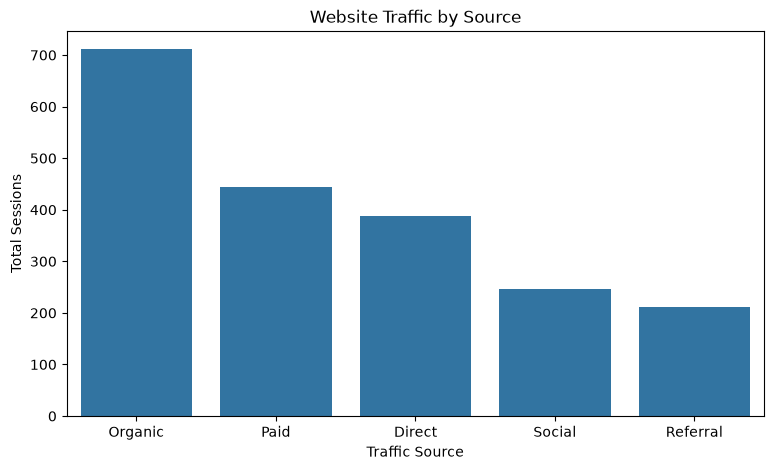

In [30]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=traffic_counts.index,
    y=traffic_counts.values
)

plt.title("Website Traffic by Source")
plt.xlabel("Traffic Source")
plt.ylabel("Total Sessions")

plt.show()

In [31]:
device_counts = df["Device"].value_counts()

print(device_counts)

Device
Mobile     979
Desktop    852
Tablet     169
Name: count, dtype: int64


In [32]:
device_percentage = df["Device"].value_counts(normalize=True) * 100

print(device_percentage.round(2))

Device
Mobile     48.95
Desktop    42.60
Tablet      8.45
Name: proportion, dtype: float64


In [33]:
device_summary = df.groupby("Device").agg(
    Total_Sessions=("Session_ID", "count"),
    Total_Conversions=("Conversion", "sum"),
    Average_Duration=("Session_Duration", "mean")
)

device_summary

,Total_Sessions,Total_Conversions,Average_Duration
Device,,,
Desktop,852,71,240.733685
Mobile,979,65,194.022880
Tablet,169,13,227.356805


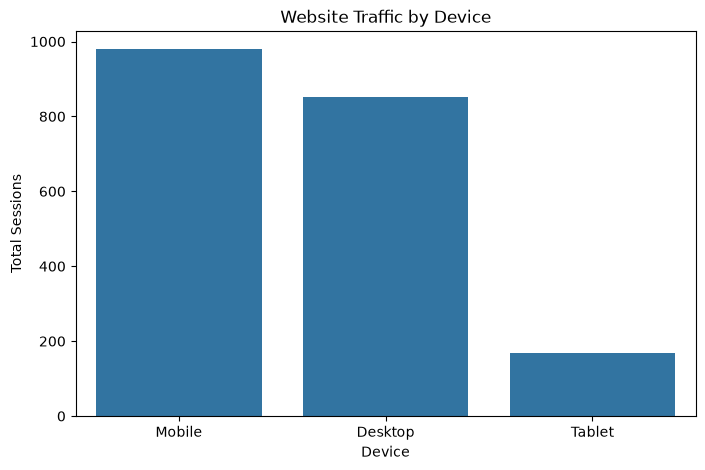

In [34]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=device_counts.index,
    y=device_counts.values
)

plt.title("Website Traffic by Device")
plt.xlabel("Device")
plt.ylabel("Total Sessions")

plt.show()

In [35]:
device_counts = df["Device"].value_counts()

print(device_counts)

Device
Mobile     979
Desktop    852
Tablet     169
Name: count, dtype: int64


In [36]:
device_percentage = df["Device"].value_counts(normalize=True) * 100

print(device_percentage.round(2))

Device
Mobile     48.95
Desktop    42.60
Tablet      8.45
Name: proportion, dtype: float64


In [37]:
device_summary = df.groupby("Device").agg(
    Total_Sessions=("Session_ID", "count"),
    Total_Conversions=("Conversion", "sum"),
    Average_Duration=("Session_Duration", "mean")
)

device_summary

,Total_Sessions,Total_Conversions,Average_Duration
Device,,,
Desktop,852,71,240.733685
Mobile,979,65,194.022880
Tablet,169,13,227.356805


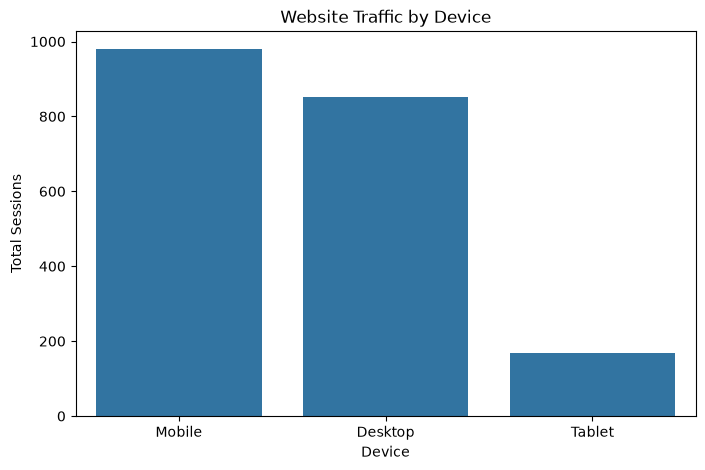

In [38]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=device_counts.index,
    y=device_counts.values
)

plt.title("Website Traffic by Device")
plt.xlabel("Device")
plt.ylabel("Total Sessions")

plt.show()

In [39]:
device_summary

,Total_Sessions,Total_Conversions,Average_Duration
Device,,,
Desktop,852,71,240.733685
Mobile,979,65,194.022880
Tablet,169,13,227.356805


In [44]:
device_bounce = df.groupby("Device")["Bounce"].mean() * 100

device_bounce.round(2)

Device
Desktop    40.02
Mobile     43.31
Tablet     45.56
Name: Bounce, dtype: float64

In [45]:
print("Average Session Duration:",
      round(df["Session_Duration"].mean(), 2), "seconds")

print("Average Pages Per Session:",
      round(df["Pages_Per_Session"].mean(), 2))

Average Session Duration: 216.74 seconds
Average Pages Per Session: 2.63


In [46]:
engagement_source = df.groupby("Traffic_Source").agg(
    Average_Duration=("Session_Duration", "mean"),
    Average_Pages=("Pages_Per_Session", "mean")
)

engagement_source.round(2)

,Average_Duration,Average_Pages
Traffic_Source,,
Direct,219.26,3.02
Organic,237.43,2.76
Paid,191.68,2.32
Referral,236.48,2.85
Social,181.20,1.99


In [47]:
engagement_device = df.groupby("Device").agg(
    Average_Duration=("Session_Duration", "mean"),
    Average_Pages=("Pages_Per_Session", "mean")
)

engagement_device.round(2)

,Average_Duration,Average_Pages
Device,,
Desktop,240.73,2.69
Mobile,194.02,2.60
Tablet,227.36,2.47


In [48]:
page_sessions = df["Page_Visited"].value_counts()

print(page_sessions)

Page_Visited
/                   370
/products           348
/blog               279
/product-details    238
/pricing            234
/about              152
/contact            151
/checkout           136
/support             92
Name: count, dtype: int64


In [49]:
page_summary = df.groupby("Page_Visited").agg(
    Total_Sessions=("Session_ID", "count"),
    Total_Conversions=("Conversion", "sum"),
    Average_Duration=("Session_Duration", "mean"),
    Bounce_Rate=("Bounce", "mean")
)

page_summary

,Total_Sessions,Total_Conversions,Average_Duration,Bounce_Rate
Page_Visited,,,,
/,370,16,218.829730,0.467568
/about,152,6,211.565132,0.394737
/blog,279,21,210.707885,0.415771
/checkout,136,22,211.705147,0.397059
/contact,151,7,213.453642,0.450331
/pricing,234,23,204.362393,0.367521
/product-details,238,32,217.825630,0.386555
/products,348,18,234.118103,0.448276
/support,92,4,210.919565,0.402174


In [50]:
page_summary["Conversion_Rate"] = (
    page_summary["Total_Conversions"] /
    page_summary["Total_Sessions"]
) * 100

page_summary = page_summary.round(2)

page_summary

,Total_Sessions,Total_Conversions,Average_Duration,Bounce_Rate,Conversion_Rate
Page_Visited,,,,,
/,370,16,218.83,0.47,4.32
/about,152,6,211.57,0.39,3.95
/blog,279,21,210.71,0.42,7.53
/checkout,136,22,211.71,0.40,16.18
/contact,151,7,213.45,0.45,4.64
/pricing,234,23,204.36,0.37,9.83
/product-details,238,32,217.83,0.39,13.45
/products,348,18,234.12,0.45,5.17
/support,92,4,210.92,0.40,4.35


In [51]:
top_pages = page_summary.sort_values(
    by="Total_Sessions",
    ascending=False
)

top_pages

,Total_Sessions,Total_Conversions,Average_Duration,Bounce_Rate,Conversion_Rate
Page_Visited,,,,,
/,370,16,218.83,0.47,4.32
/products,348,18,234.12,0.45,5.17
/blog,279,21,210.71,0.42,7.53
/product-details,238,32,217.83,0.39,13.45
/pricing,234,23,204.36,0.37,9.83
/about,152,6,211.57,0.39,3.95
/contact,151,7,213.45,0.45,4.64
/checkout,136,22,211.71,0.40,16.18
/support,92,4,210.92,0.40,4.35


In [52]:
low_pages = page_summary.sort_values(
    by="Total_Sessions",
    ascending=True
)

low_pages

,Total_Sessions,Total_Conversions,Average_Duration,Bounce_Rate,Conversion_Rate
Page_Visited,,,,,
/support,92,4,210.92,0.40,4.35
/checkout,136,22,211.71,0.40,16.18
/contact,151,7,213.45,0.45,4.64
/about,152,6,211.57,0.39,3.95
/pricing,234,23,204.36,0.37,9.83
/product-details,238,32,217.83,0.39,13.45
/blog,279,21,210.71,0.42,7.53
/products,348,18,234.12,0.45,5.17
/,370,16,218.83,0.47,4.32


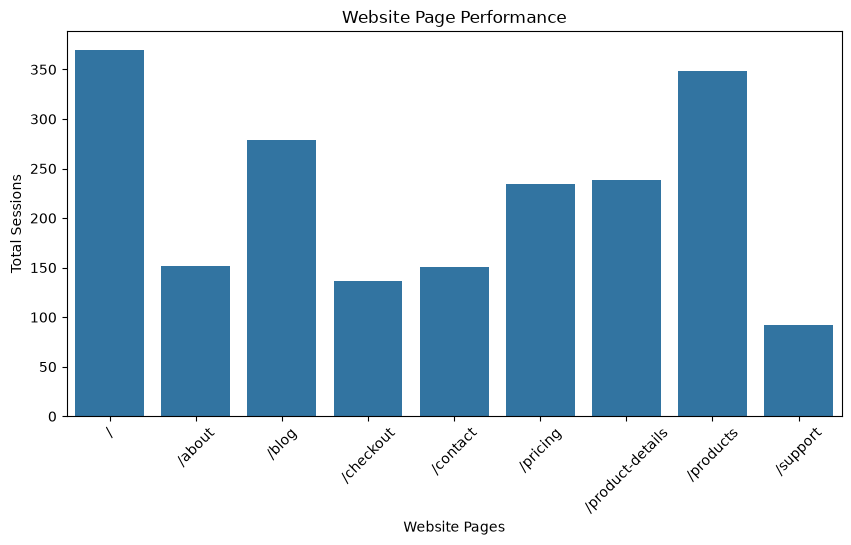

In [53]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=page_summary.index,
    y=page_summary["Total_Sessions"]
)

plt.title("Website Page Performance")
plt.xlabel("Website Pages")
plt.ylabel("Total Sessions")
plt.xticks(rotation=45)

plt.show()

In [54]:
page_summary

,Total_Sessions,Total_Conversions,Average_Duration,Bounce_Rate,Conversion_Rate
Page_Visited,,,,,
/,370,16,218.83,0.47,4.32
/about,152,6,211.57,0.39,3.95
/blog,279,21,210.71,0.42,7.53
/checkout,136,22,211.71,0.40,16.18
/contact,151,7,213.45,0.45,4.64
/pricing,234,23,204.36,0.37,9.83
/product-details,238,32,217.83,0.39,13.45
/products,348,18,234.12,0.45,5.17
/support,92,4,210.92,0.40,4.35


In [55]:
page_summary["Bounce_Rate"] = (
    df.groupby("Page_Visited")["Bounce"].mean() * 100
)

page_summary = page_summary.round(2)

page_summary

,Total_Sessions,Total_Conversions,Average_Duration,Bounce_Rate,Conversion_Rate
Page_Visited,,,,,
/,370,16,218.83,46.76,4.32
/about,152,6,211.57,39.47,3.95
/blog,279,21,210.71,41.58,7.53
/checkout,136,22,211.71,39.71,16.18
/contact,151,7,213.45,45.03,4.64
/pricing,234,23,204.36,36.75,9.83
/product-details,238,32,217.83,38.66,13.45
/products,348,18,234.12,44.83,5.17
/support,92,4,210.92,40.22,4.35


In [56]:
page_summary.sort_values(
    by="Conversion_Rate",
    ascending=False
)

,Total_Sessions,Total_Conversions,Average_Duration,Bounce_Rate,Conversion_Rate
Page_Visited,,,,,
/checkout,136,22,211.71,39.71,16.18
/product-details,238,32,217.83,38.66,13.45
/pricing,234,23,204.36,36.75,9.83
/blog,279,21,210.71,41.58,7.53
/products,348,18,234.12,44.83,5.17
/contact,151,7,213.45,45.03,4.64
/support,92,4,210.92,40.22,4.35
/,370,16,218.83,46.76,4.32
/about,152,6,211.57,39.47,3.95


In [57]:
page_summary.sort_values(
    by="Bounce_Rate",
    ascending=False
)

,Total_Sessions,Total_Conversions,Average_Duration,Bounce_Rate,Conversion_Rate
Page_Visited,,,,,
/,370,16,218.83,46.76,4.32
/contact,151,7,213.45,45.03,4.64
/products,348,18,234.12,44.83,5.17
/blog,279,21,210.71,41.58,7.53
/support,92,4,210.92,40.22,4.35
/checkout,136,22,211.71,39.71,16.18
/about,152,6,211.57,39.47,3.95
/product-details,238,32,217.83,38.66,13.45
/pricing,234,23,204.36,36.75,9.83


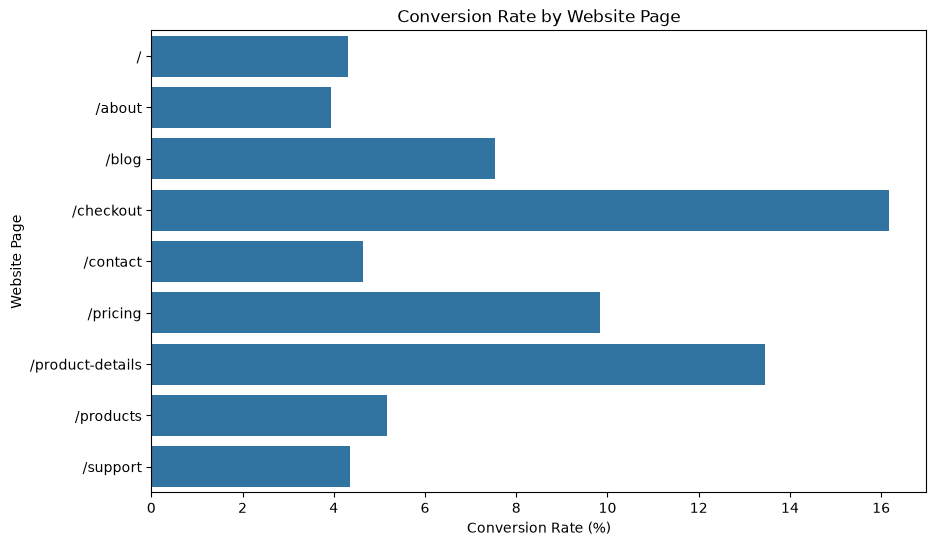

In [58]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=page_summary["Conversion_Rate"],
    y=page_summary.index
)

plt.title("Conversion Rate by Website Page")
plt.xlabel("Conversion Rate (%)")
plt.ylabel("Website Page")

plt.show()

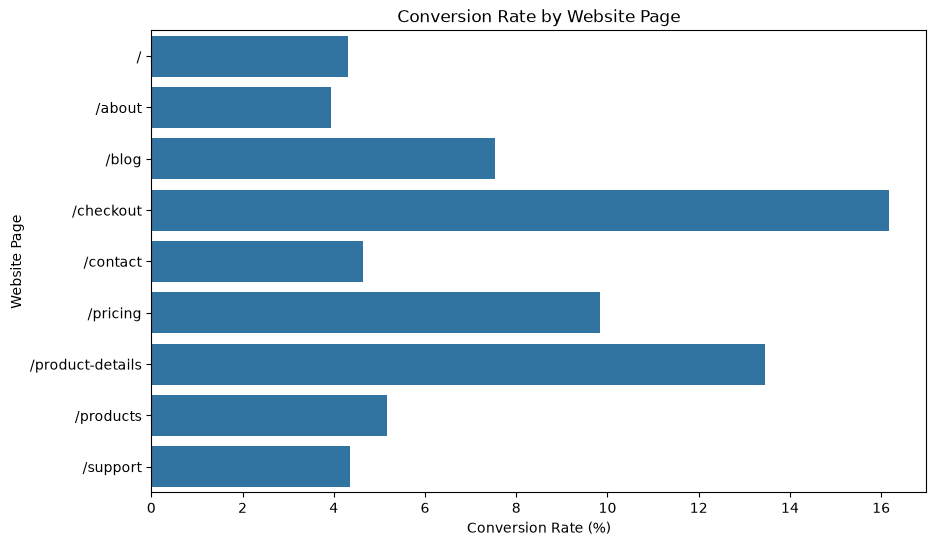

In [59]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=page_summary["Conversion_Rate"],
    y=page_summary.index
)

plt.title("Conversion Rate by Website Page")
plt.xlabel("Conversion Rate (%)")
plt.ylabel("Website Page")

plt.show()

In [60]:
df["Month"] = df["Date"].dt.month_name()

monthly_traffic = df.groupby("Month")["Session_ID"].count()

monthly_traffic

Month
April        172
August       178
December     160
February     175
January      184
July         165
June         173
March        141
May          174
November     166
October      152
September    160
Name: Session_ID, dtype: int64

In [61]:
monthly_traffic = df.groupby(
    df["Date"].dt.to_period("M")
)["Session_ID"].count()

monthly_traffic

Date
2025-01    184
2025-02    175
2025-03    141
2025-04    172
2025-05    174
2025-06    173
2025-07    165
2025-08    178
2025-09    160
2025-10    152
2025-11    166
2025-12    160
Freq: M, Name: Session_ID, dtype: int64

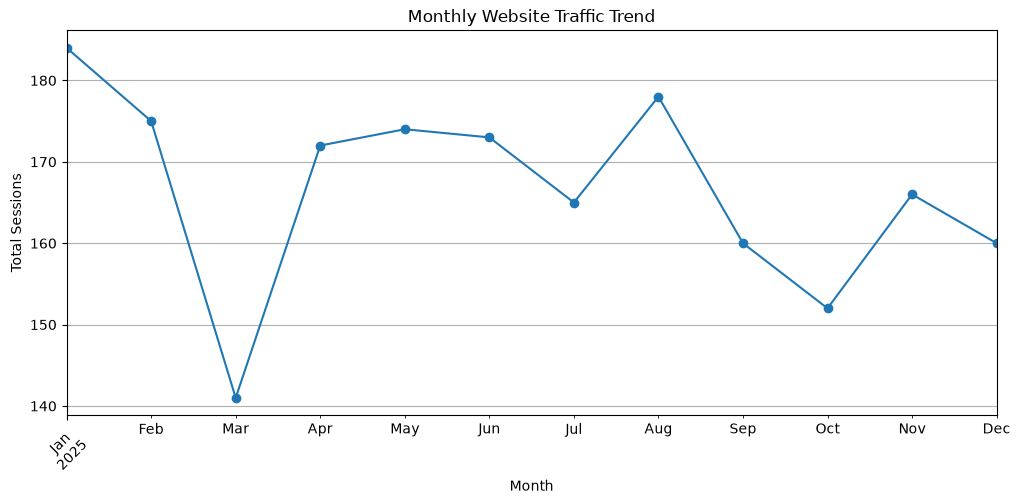

In [62]:
plt.figure(figsize=(12, 5))

monthly_traffic.plot(kind="line", marker="o")

plt.title("Monthly Website Traffic Trend")
plt.xlabel("Month")
plt.ylabel("Total Sessions")

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [63]:
monthly_traffic = df.groupby(
    df["Date"].dt.to_period("M")
)["Session_ID"].count()

monthly_traffic

Date
2025-01    184
2025-02    175
2025-03    141
2025-04    172
2025-05    174
2025-06    173
2025-07    165
2025-08    178
2025-09    160
2025-10    152
2025-11    166
2025-12    160
Freq: M, Name: Session_ID, dtype: int64

In [64]:
print("Highest Traffic Month:", monthly_traffic.idxmax())

print("Lowest Traffic Month:", monthly_traffic.idxmin())

Highest Traffic Month: 2025-01
Lowest Traffic Month: 2025-03


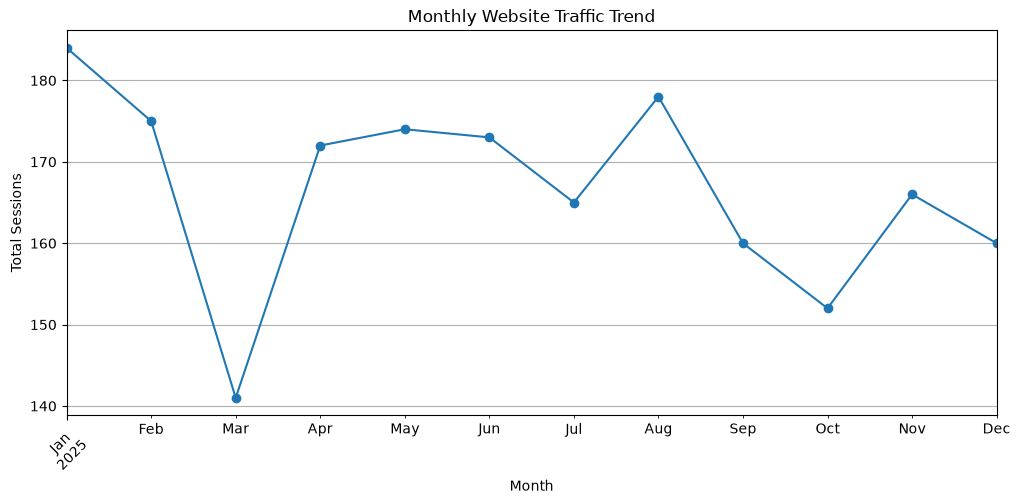

In [65]:
plt.figure(figsize=(12, 5))

monthly_traffic.plot(kind="line", marker="o")

plt.title("Monthly Website Traffic Trend")
plt.xlabel("Month")
plt.ylabel("Total Sessions")

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [66]:
print("Highest Traffic Month:")
print(monthly_traffic.idxmax(), monthly_traffic.max())

print("Lowest Traffic Month:")
print(monthly_traffic.idxmin(), monthly_traffic.min())

Highest Traffic Month:
2025-01 184
Lowest Traffic Month:
2025-03 141


In [67]:
total_conversions = df["Conversion"].sum()

total_sessions = df["Session_ID"].count()

conversion_rate = (total_conversions / total_sessions) * 100

print("Total Conversions:", total_conversions)
print("Total Sessions:", total_sessions)
print("Conversion Rate:", round(conversion_rate, 2), "%")

Total Conversions: 149
Total Sessions: 2000
Conversion Rate: 7.45 %


In [68]:
monthly_conversions = df.groupby(
    df["Date"].dt.to_period("M")
)["Conversion"].sum()

monthly_conversions

Date
2025-01    12
2025-02    18
2025-03     6
2025-04    13
2025-05    13
2025-06    13
2025-07     7
2025-08    14
2025-09    15
2025-10    11
2025-11     8
2025-12    19
Freq: M, Name: Conversion, dtype: int64

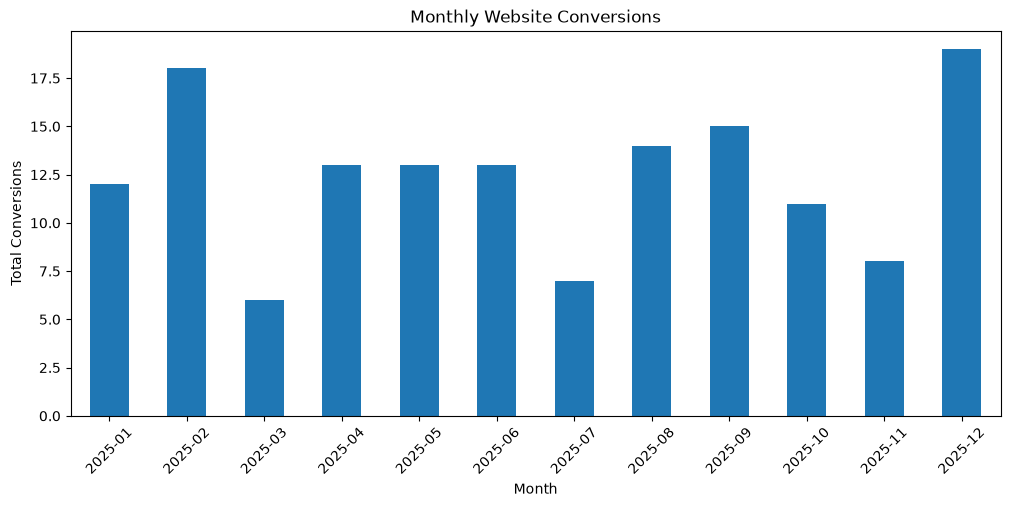

In [69]:
plt.figure(figsize=(12, 5))

monthly_conversions.plot(kind="bar")

plt.title("Monthly Website Conversions")
plt.xlabel("Month")
plt.ylabel("Total Conversions")

plt.xticks(rotation=45)
plt.show()

In [70]:
monthly_summary = df.groupby(
    df["Date"].dt.to_period("M")
).agg(
    Total_Sessions=("Session_ID", "count"),
    Total_Conversions=("Conversion", "sum")
)

monthly_summary["Conversion_Rate"] = (
    monthly_summary["Total_Conversions"] /
    monthly_summary["Total_Sessions"]
) * 100

monthly_summary.round(2)

,Total_Sessions,Total_Conversions,Conversion_Rate
Date,,,
2025-01,184,12,6.52
2025-02,175,18,10.29
2025-03,141,6,4.26
2025-04,172,13,7.56
2025-05,174,13,7.47
2025-06,173,13,7.51
2025-07,165,7,4.24
2025-08,178,14,7.87
2025-09,160,15,9.38


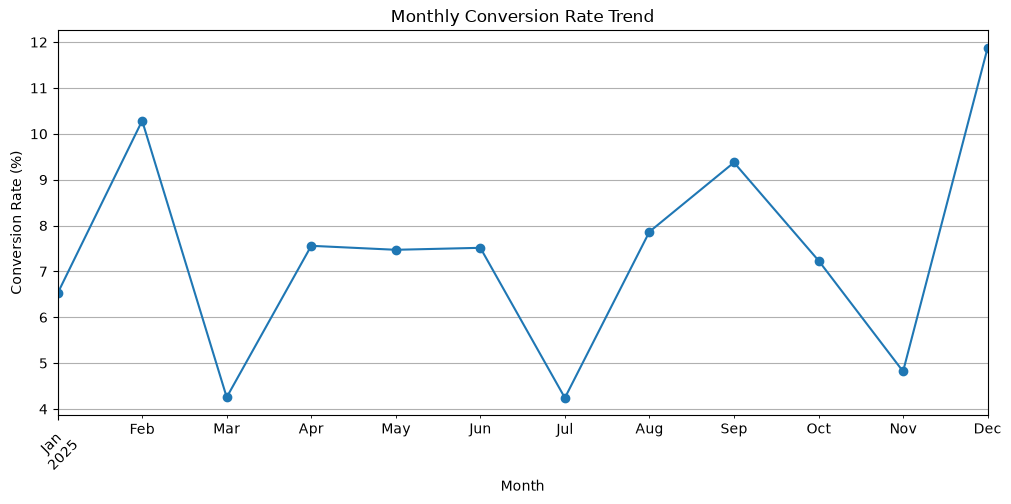

In [71]:
plt.figure(figsize=(12, 5))

monthly_summary["Conversion_Rate"].plot(
    kind="line",
    marker="o"
)

plt.title("Monthly Conversion Rate Trend")
plt.xlabel("Month")
plt.ylabel("Conversion Rate (%)")

plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [72]:
print("Highest Conversion Month:")
print(monthly_summary["Conversion_Rate"].idxmax())

print("Highest Rate:")
print(monthly_summary["Conversion_Rate"].max())

print("Lowest Conversion Month:")
print(monthly_summary["Conversion_Rate"].idxmin())

print("Lowest Rate:")
print(monthly_summary["Conversion_Rate"].min())

Highest Conversion Month:
2025-12
Highest Rate:
11.875
Lowest Conversion Month:
2025-07
Lowest Rate:
4.242424242424243
